In [1]:
!pip install -q pymc-marketing==1.3.0 nutpie

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.


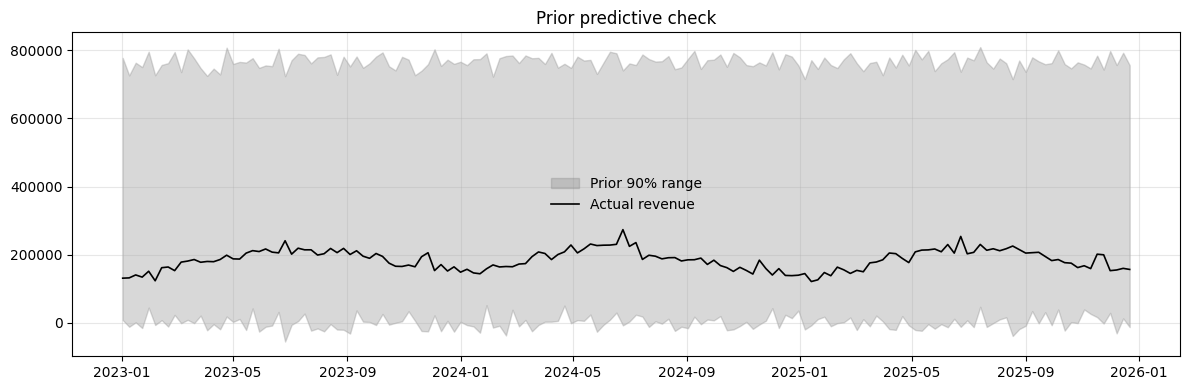

Output()

Output()

                                   mean       sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
intercept_contribution             0.45    0.056     0.35     0.53     1162     1343  1.00    0.0017   0.0021
saturation_beta[google_search]     0.33     0.22      0.1     0.73      742     1010  1.01     0.008    0.012
saturation_beta[meta]             0.105      0.1    0.023     0.26     1302     1447  1.00    0.0029   0.0077
saturation_beta[microsoft]        0.079    0.053   0.0091     0.17     1296     1142  1.00    0.0014   0.0009
saturation_beta[youtube]          0.044    0.048   0.0039     0.13     2352     1853  1.00   0.00091   0.0017
saturation_lam[google_search]      1.78     1.04     0.51      3.6      999     1046  1.01     0.031    0.037
saturation_lam[meta]                2.6     1.77      0.5      5.9     1315     1293  1.00     0.044    0.034
saturation_lam[microsoft]          2.81      1.7     0.79        6     2119     2289  1.00     0.037    0.036
saturation

Output()


In-sample R²: 0.922 | MAPE: 3.6%


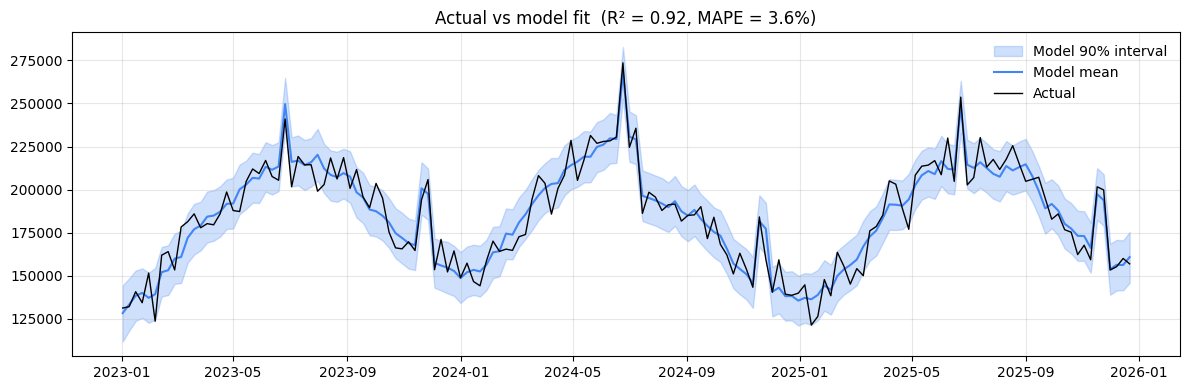

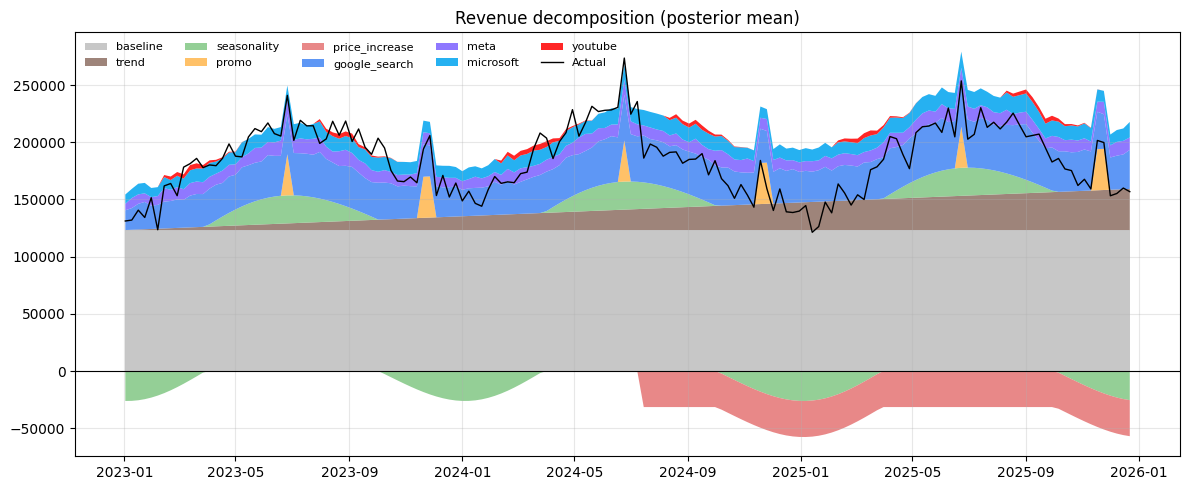


Media-driven share of revenue (model): 30.7%

Total contribution by component (USD):
baseline          19227958.0
google_search      5182697.0
trend              2802647.0
microsoft          1858125.0
meta               1640331.0
promo               323818.0
youtube             190027.0
seasonality          13883.0
price_increase    -2394754.0


In [1]:
# ============================================================
# Project 3 - Marketing Mix Model
# Step 3: Fit a Bayesian MMM with PyMC-Marketing
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
from pymc_extras.prior import Prior
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)
SEED = 42

URL = "https://raw.githubusercontent.com/paolofelix/marketing-mix-model/main/data/mmm_data.csv"
df = pd.read_csv(URL, parse_dates=["date"])

channels = ["google_search", "meta", "microsoft", "youtube"]

# Controls (kept on a 0-1 scale so the sampler behaves)
df["trend"] = np.arange(len(df)) / (len(df) - 1)            # organic growth
df["price_increase"] = (df["price_index"] > 1).astype(int)  # 0 before, 1 after the +10% price change
controls = ["promo", "price_increase", "trend"]

X = df[["date"] + channels + controls]
y = df["revenue"]

# ------------------------------------------------------------
# 1. Priors - where domain knowledge goes in
# ------------------------------------------------------------
# a) Channel effect size scaled by share of spend: a channel we spend more on
#    is expected (a priori) to drive more revenue. Helps separate Google vs Microsoft.
spend_share = df[channels].sum() / df[channels].sum().sum()
beta_sigma = (spend_share / spend_share.mean() * 0.5).to_numpy()

# b) Carryover (adstock) by channel type:
#    search = short (people search when ready to buy), social = medium, video = long.
#                     google  meta  microsoft  youtube
adstock_a = np.array([1,      2,    1,         3])
adstock_b = np.array([3,      3,    3,         2])

model_config = {
    "intercept": Prior("Normal", mu=0.5, sigma=0.3),
    "saturation_beta": Prior("HalfNormal", sigma=beta_sigma, dims="channel"),
    "saturation_lam": Prior("Gamma", alpha=3, beta=1, dims="channel"),
    "adstock_alpha": Prior("Beta", alpha=adstock_a, beta=adstock_b, dims="channel"),
    "gamma_control": Prior("Normal", mu=0, sigma=0.5, dims="control"),
    "gamma_fourier": Prior("Laplace", mu=0, b=0.2, dims="fourier_mode"),
    "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
}

mmm = MMM(
    date_column="date",
    channel_columns=channels,
    control_columns=controls,
    target_column="revenue",
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
    model_config=model_config,
)

# ------------------------------------------------------------
# 2. Prior predictive check: do the priors produce plausible revenue
#    BEFORE the model sees the data?
# ------------------------------------------------------------
mmm.build_model(X, y)
prior = mmm.sample_prior_predictive(X, y, samples=500, random_seed=SEED)
y_scale = float(mmm.get_scales_as_xarray()["target_scale"])
prior_y = prior["y"].values.reshape(-1, len(df)) * y_scale

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(df["date"], *np.percentile(prior_y, [5, 95], axis=0), color="grey", alpha=0.3, label="Prior 90% range")
ax.plot(df["date"], y, color="black", lw=1.2, label="Actual revenue")
ax.set_title("Prior predictive check")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/05_prior_predictive.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 3. Fit with MCMC (nutpie sampler: ~1-3 min on Colab)
# ------------------------------------------------------------
mmm.fit(
    X, y,
    chains=4, draws=1000, tune=1500,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED,
)

# ------------------------------------------------------------
# 4. Convergence diagnostics
#    Good: 0 divergences, r_hat <= 1.01, ESS > 400
# ------------------------------------------------------------
params = ["intercept_contribution", "saturation_beta", "saturation_lam",
          "adstock_alpha", "gamma_control", "y_sigma"]
summary = az.summary(mmm.idata, var_names=params)
print(summary)
divergences = int(mmm.idata.sample_stats["diverging"].sum())
print(f"\nDivergences: {divergences} | max r_hat: {summary['r_hat'].astype(float).max():.3f} "
      f"| min ESS: {summary['ess_bulk'].astype(float).min():.0f}")

# ------------------------------------------------------------
# 5. In-sample fit: actual vs predicted
# ------------------------------------------------------------
post = mmm.sample_posterior_predictive(X, extend_idata=True, combined=True, random_seed=SEED)
pred = post["y"].transpose("date", "sample").values * y_scale   # shape: (weeks, samples)
pred_mean = pred.mean(axis=1)
lo, hi = np.percentile(pred, [5, 95], axis=1)

r2 = 1 - ((y - pred_mean) ** 2).sum() / ((y - y.mean()) ** 2).sum()
mape = (np.abs(y - pred_mean) / y).mean()
print(f"\nIn-sample R²: {r2:.3f} | MAPE: {mape:.1%}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(df["date"], lo, hi, color="#4285F4", alpha=0.25, label="Model 90% interval")
ax.plot(df["date"], pred_mean, color="#4285F4", lw=1.5, label="Model mean")
ax.plot(df["date"], y, color="black", lw=1, label="Actual")
ax.set_title(f"Actual vs model fit  (R² = {r2:.2f}, MAPE = {mape:.1%})")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/06_model_fit.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 6. Revenue decomposition: what drove revenue each week?
# ------------------------------------------------------------
post_mean = mmm.idata.posterior.mean(("chain", "draw"))
decomp = pd.DataFrame(index=df["date"])
decomp["baseline"] = float(post_mean["intercept_contribution"]) * y_scale
decomp["seasonality"] = post_mean["yearly_seasonality_contribution"].values * y_scale
for c in controls:
    decomp[c] = post_mean["control_contribution"].sel(control=c).values * y_scale
for ch in channels:
    decomp[ch] = post_mean["channel_contribution"].sel(channel=ch).values * y_scale

order = ["baseline", "trend", "seasonality", "promo", "price_increase"] + channels
palette = ["#BDBDBD", "#8D6E63", "#81C784", "#FFB74D", "#E57373",
           "#4285F4", "#7B61FF", "#00A4EF", "#FF0000"]
pos = decomp[order].clip(lower=0)
neg = decomp[order].clip(upper=0)
fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(df["date"], pos.T.values, labels=order, colors=palette, alpha=0.85)
ax.stackplot(df["date"], neg.T.values, colors=palette, alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.plot(df["date"], y, color="black", lw=1, label="Actual")
ax.set_title("Revenue decomposition (posterior mean)")
ax.legend(loc="upper left", ncol=5, fontsize=8, frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/07_decomposition.png", dpi=150)
plt.show()

media_share = decomp[channels].sum().sum() / y.sum()
print(f"\nMedia-driven share of revenue (model): {media_share:.1%}")
print("\nTotal contribution by component (USD):")
print(decomp.sum().round(0).sort_values(ascending=False).to_string())